---
title: "Week 8B: Street Network Analysis"
format:
  html:
    toc: true
    toc-depth: 2
    number-sections: true
    code-fold: false
    embed-resources: true
    theme: cosmo
execute:
  enabled: false
---

## Overview

How can we find a shortest walking route along a sidewalk network?

In this lab, we move from a small **NetworkX** graph to Philadelphia sidewalk data. By the end, you will be able to:

- Describe nodes, edges, neighbors, and edge weights.
- Read sidewalk lines with GeoPandas and build an undirected network.
- Find the largest connected component and snap locations to its nodes.
- Calculate, map, and export a shortest route using the original sidewalk geometry.

This is a **static, distance-based walking-network demonstration**. It does not model live traffic, driving restrictions, or measured travel times.

**Suggested class flow:** graph basics (10 minutes), data and network construction (15 minutes), routing and visualization (15 minutes), practice (10 minutes).

## Setup

Use a Python environment with `geopandas`, `networkx`, `numpy`, and `matplotlib`. If needed, install them in the active notebook kernel with `%pip install geopandas networkx numpy matplotlib`, then restart the kernel.

Open this notebook from the lab folder, or from the course `public` folder. The supplied data are in `data/sidewalk.zip`; GeoPandas can read the ZIP directly, so extraction is unnecessary. Run cells from top to bottom; use **Restart Kernel and Run All** before class.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import display

plt.rcParams.update({"figure.figsize": (9, 6), "font.size": 11})
print(f"GeoPandas {gpd.__version__} | NetworkX {nx.__version__}")

GeoPandas 0.13.2 | NetworkX 3.1


## Graph basics

A **node** represents a location; an **edge** connects two locations. `nx.Graph()` is undirected: an edge can be traversed in either direction. Use a directed graph when direction matters.

### Add nodes and weighted edges

Here, edge weights are distances in arbitrary units. All edges receive a weight so the routing calculation is explicit.

In [2]:
toy = nx.Graph()
toy.add_nodes_from([
    ("A", {"place": "Home"}),
    ("B", {"place": "Library"}),
    ("C", {"place": "Park"}),
    ("D", {"place": "School"}),
])
toy.add_weighted_edges_from([
    ("A", "B", 2), ("B", "D", 2),
    ("A", "C", 1), ("C", "D", 6), ("A", "D", 7),
])

print("Nodes:", list(toy.nodes(data=True)))
print("Edges:", list(toy.edges(data=True)))
print("Neighbors of A:", list(toy.neighbors("A")))
print("Degree of A:", toy.degree["A"])
print("A–B attributes:", toy.edges["A", "B"])

Nodes: [('A', {'place': 'Home'}), ('B', {'place': 'Library'}), ('C', {'place': 'Park'}), ('D', {'place': 'School'})]
Edges: [('A', 'B', {'weight': 2}), ('A', 'C', {'weight': 1}), ('A', 'D', {'weight': 7}), ('B', 'D', {'weight': 2}), ('C', 'D', {'weight': 6})]
Neighbors of A: ['B', 'C', 'D']
Degree of A: 3
A–B attributes: {'weight': 2}


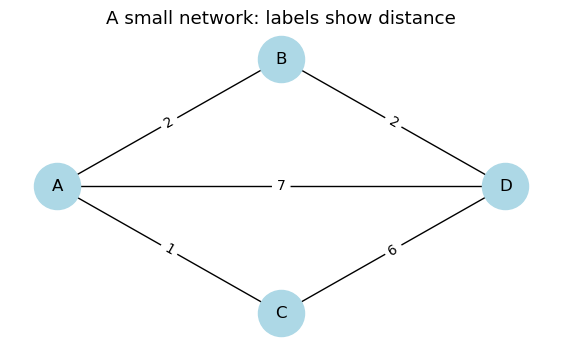

In [3]:
positions = {"A": (0, 0), "B": (1, 1), "C": (1, -1), "D": (2, 0)}
fig, ax = plt.subplots(figsize=(7, 4))
nx.draw(toy, positions, with_labels=True, node_color="lightblue",
        node_size=1100, ax=ax)
nx.draw_networkx_edge_labels(
    toy, positions, edge_labels=nx.get_edge_attributes(toy, "weight"), ax=ax
)
ax.set_title("A small network: labels show distance")
plt.show()

### Fewest edges versus shortest distance

**Predict first:** which route from A to D has the fewest edges? Which has the smallest total distance?

Without `weight`, shortest path minimizes the number of edges. With `weight="weight"`, it minimizes the sum of that edge attribute.

In [4]:
fewest_edges = nx.shortest_path(toy, "A", "D")
shortest_distance = nx.shortest_path(toy, "A", "D", weight="weight")
distance = nx.shortest_path_length(toy, "A", "D", weight="weight")

print("Fewest edges:", fewest_edges)
print("Shortest distance:", shortest_distance)
print("Total distance:", distance)

Fewest edges: ['A', 'D']
Shortest distance: ['A', 'B', 'D']
Total distance: 4


## Read and prepare the sidewalk data

### Locate and inspect the data

A line feature is a candidate network edge. Its first and last coordinates become nodes. Intermediate coordinates preserve the shape of the sidewalk; they are not automatically intersections.

In [5]:
lab_dir = Path.cwd()
if not (lab_dir / "data/sidewalk.zip").exists():
    lab_dir = lab_dir / "labs/week-8-network-analysis"
data_path = lab_dir / "data/sidewalk.zip"
if not data_path.exists():
    raise FileNotFoundError("Open the notebook from the lab or public folder; data/sidewalk.zip is required.")

sidewalks = gpd.read_file(f"zip://{data_path.resolve()}")
if sidewalks.crs is None:
    raise ValueError("The source CRS must be known before measuring distances.")
print(f"Source features: {len(sidewalks):,}")
print("Source CRS:", sidewalks.crs)
print("Source coordinate unit:", sidewalks.crs.axis_info[0].unit_name)
print(sidewalks.geom_type.value_counts())
display(sidewalks[["objectid", "geometry"]].head())

Source features: 130,964
Source CRS: EPSG:2272
Source coordinate unit: US survey foot
LineString         130962
MultiLineString         2
dtype: int64


,objectid,geometry
0,67,"LINESTRING (2674629.020 233887.423, 2674638.45..."
1,70,"LINESTRING (2677370.914 234099.038, 2677331.09..."
2,73,"LINESTRING (2676819.995 233998.894, 2676874.84..."
3,108,"LINESTRING (2677398.898 234090.960, 2677452.66..."
4,112,"LINESTRING (2677418.023 234179.818, 2677382.32..."


### Measure length in meters

The supplied data use Pennsylvania State Plane coordinates in **US survey feet**. Reproject to a local UTM CRS before calculating lengths in meters. `to_crs()` transforms coordinates; `set_crs()` only assigns a CRS label.

Split multipart features into separate lines and report excluded empty, invalid, or zero-length geometries. Keep `objectid` for tracing results back to the source and assign a unique `segment_id` to each line part.

In [6]:
usable = sidewalks.geometry.notna() & ~sidewalks.geometry.is_empty
lines = sidewalks.loc[usable, ["objectid", "geometry"]].copy()
lines = lines.explode(index_parts=False).reset_index(drop=True)
valid = lines.geom_type.eq("LineString") & lines.geometry.is_valid
print(f"Excluded missing/empty features: {(~usable).sum():,}")
print(f"Excluded invalid/non-line parts: {(~valid).sum():,}")
lines = lines.loc[valid].copy()
metric_crs = lines.estimate_utm_crs()
lines = lines.to_crs(metric_crs)
lines["length_m"] = lines.length
print(f"Excluded zero-length parts: {(lines.length_m <= 0).sum():,}")
lines = lines.loc[lines.length_m > 0].reset_index(drop=True)
lines.index.name = "segment_id"
print(f"Prepared line parts: {len(lines):,} | CRS: {lines.crs}")
display(lines[["objectid", "length_m"]].head())

Excluded missing/empty features: 0
Excluded invalid/non-line parts: 0


Excluded zero-length parts: 0
Prepared line parts: 130,966 | CRS: EPSG:32618


,objectid,length_m
segment_id,,
0,67,132.997234
1,70,17.372354
2,73,16.783956
3,108,16.559983
4,112,11.438856


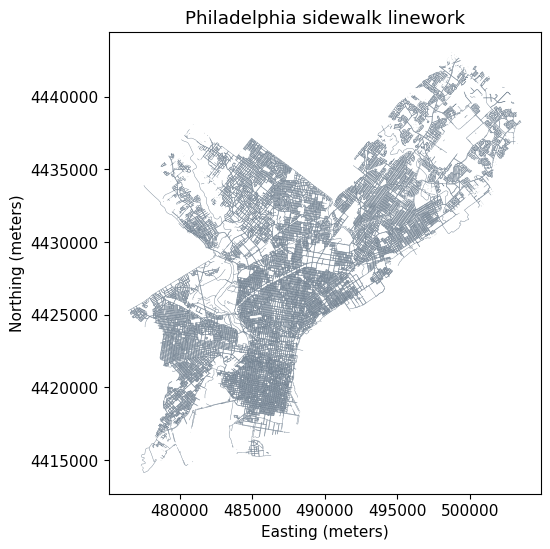

In [7]:
fig, ax = plt.subplots()
lines.plot(ax=ax, color="slategray", linewidth=0.3)
ax.set_title("Philadelphia sidewalk linework")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")
ax.ticklabel_format(style="plain", useOffset=False)
plt.show()

## Build a sidewalk network

### Turn endpoints into nodes

Use a `MultiGraph` to retain multiple sidewalk segments connecting the same pair of endpoints. Each edge stores its `segment_id` and `length_m`; the GeoDataFrame retains the full geometry.

**Model assumptions:** sidewalks are traversable in both directions, and only exactly matching line endpoints connect. Crossing lines are not automatically connected. Gaps, unsplit intersections, grade separation, and missing crossings require additional topology work for a real routing application.

In [8]:
network = nx.MultiGraph(crs=lines.crs.to_string())
for segment_id, row in lines.iterrows():
    coordinates = row.geometry.coords
    start = tuple(coordinates[0][:2])
    end = tuple(coordinates[-1][:2])
    network.add_edge(
        start, end, key=segment_id,
        segment_id=segment_id, length_m=float(row.length_m),
    )

print(f"Nodes: {network.number_of_nodes():,}")
print(f"Edges: {network.number_of_edges():,}")

Nodes: 91,261
Edges: 130,966


### Inspect connectivity

A connected component is a group of nodes reachable from one another. Routes cannot cross disconnected components.

Select the component with the **most nodes**, not the first component returned by an iterator. Report how much data remains: restricting the demonstration to one component does not repair the full network.

In [9]:
components = sorted(nx.connected_components(network), key=len, reverse=True)
if not components:
    raise ValueError("No network nodes were created.")
graph = network.subgraph(components[0]).copy()
print(f"Connected components: {len(components):,}")
print("Five largest component sizes:", [len(c) for c in components[:5]])
print(f"Selected component: {graph.number_of_nodes():,} nodes, "
      f"{graph.number_of_edges():,} edges")
print(f"Node coverage: {graph.number_of_nodes() / network.number_of_nodes():.1%}")

Connected components: 989
Five largest component sizes: [88516, 77, 68, 57, 40]
Selected component: 88,516 nodes, 129,104 edges
Node coverage: 97.0%


## Snap locations and find a route

### Find the nearest network node

For a point `(x, y)`, calculate Euclidean distance to each node and select the minimum. Squared distances give the same nearest node without computing a square root for every node.

The point and the graph must use the **same projected CRS**. This simple NumPy search is suitable for a demonstration; a spatial index is preferable for many queries. Snapping to a node differs from snapping to the nearest position along an edge.

In [10]:
node_list = list(graph.nodes)
node_array = np.asarray(node_list, dtype=float)

def nearest_node(xy):
    """Return the nearest node and straight-line snap distance in meters."""
    squared_distances = ((node_array - np.asarray(xy)) ** 2).sum(axis=1)
    nearest_index = int(squared_distances.argmin())
    return node_list[nearest_index], float(np.sqrt(squared_distances[nearest_index]))

### Choose demonstration locations

To keep the example reproducible, choose a node near the component's center, then a destination roughly 1 km away **along the network** (or the farthest reachable node if the component is smaller). Offset these locations slightly to demonstrate snapping arbitrary points.

For your own locations, transform a point GeoDataFrame with `.to_crs(lines.crs)` and pass its point coordinates to `nearest_node()`. Always inspect the snap distances; a distant match can produce a misleading route.

In [11]:
anchor, _ = nearest_node(node_array.mean(axis=0))
distances_from_anchor = nx.single_source_dijkstra_path_length(
    graph, anchor, weight="length_m"
)
target_distance_m = min(1000, max(distances_from_anchor.values()))
destination_anchor = min(
    distances_from_anchor,
    key=lambda node: abs(distances_from_anchor[node] - target_distance_m),
)
origin_xy = np.asarray(anchor) + [3, -2]
destination_xy = np.asarray(destination_anchor) + [-3, 2]
origin, origin_snap_m = nearest_node(origin_xy)
destination, destination_snap_m = nearest_node(destination_xy)
print(f"Origin snap distance: {origin_snap_m:.1f} m")
print(f"Destination snap distance: {destination_snap_m:.1f} m")

Origin snap distance: 3.6 m
Destination snap distance: 3.6 m


### Calculate the shortest route

`length_m` is the edge cost. For parallel edges, NetworkX uses the smallest cost between each pair of nodes. Recover that same edge when selecting the route geometry.

The reported route distance includes network edges only; the short connections from the input points to their snapped nodes are excluded.

In [12]:
route_distance_m, route_nodes = nx.single_source_dijkstra(
    graph, origin, target=destination, weight="length_m"
)
route_segment_ids = []
for u, v in zip(route_nodes[:-1], route_nodes[1:]):
    edge_options = graph[u][v]
    best_key = min(edge_options, key=lambda key: edge_options[key]["length_m"])
    route_segment_ids.append(edge_options[best_key]["segment_id"])

if not route_segment_ids:
    raise ValueError("Both points snapped to the same node; choose locations farther apart.")
route = lines.loc[route_segment_ids].copy()
route["route_order"] = np.arange(1, len(route) + 1)
print(f"Route distance: {route_distance_m:,.1f} m ({route_distance_m / 1000:.2f} km)")
print(f"Route segments: {len(route):,}")
assert np.isclose(route.length_m.sum(), route_distance_m)
display(route[["route_order", "objectid", "length_m"]].head())

Route distance: 999.8 m (1.00 km)
Route segments: 31


,route_order,objectid,length_m
segment_id,,,
39953,1,97584,6.030703
74544,2,132177,64.881374
17895,3,75522,10.092707
59039,4,116671,2.931842
52272,5,109903,76.921304


## Map and export the route

### Preserve the original sidewalk geometry

Plot the selected line features, not straight lines joining the route nodes. Drawing endpoint-to-endpoint chords would lose the curves in the source geometry. The dashed connectors below show the snapping step, not additional modeled sidewalks.

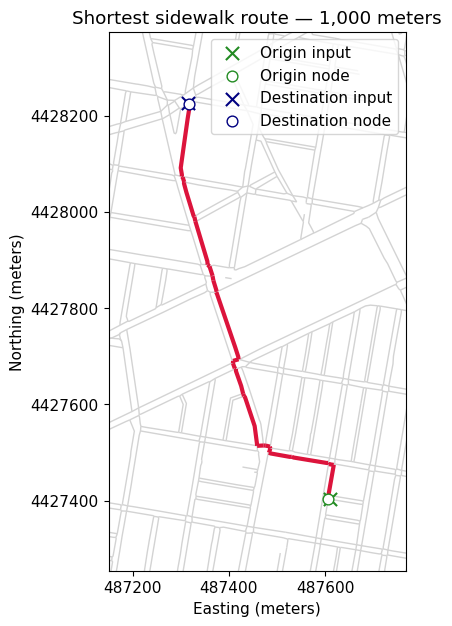

In [13]:
xmin, ymin, xmax, ymax = route.total_bounds
padding = 150
bounds = lines.bounds
in_view = (
    (bounds.maxx >= xmin-padding) & (bounds.minx <= xmax+padding)
    & (bounds.maxy >= ymin-padding) & (bounds.miny <= ymax+padding)
)
nearby = lines.loc[in_view]
fig, ax = plt.subplots(figsize=(10, 7))
nearby.plot(ax=ax, color="lightgray", linewidth=1)
route.plot(ax=ax, color="crimson", linewidth=3, zorder=3)
for xy, node, color, label in [
    (origin_xy, origin, "forestgreen", "Origin"),
    (destination_xy, destination, "navy", "Destination"),
]:
    ax.plot([xy[0], node[0]], [xy[1], node[1]], "--", color=color, zorder=4)
    ax.scatter(*xy, color=color, marker="x", s=90, label=f"{label} input", zorder=5)
    ax.scatter(*node, facecolors="white", edgecolors=color, s=60,
               label=f"{label} node", zorder=5)
ax.set_xlim(xmin-padding, xmax+padding)
ax.set_ylim(ymin-padding, ymax+padding)
ax.set_title(f"Shortest sidewalk route — {route_distance_m:,.0f} meters")
ax.set_xlabel("Easting (meters)")
ax.set_ylabel("Northing (meters)")
ax.ticklabel_format(style="plain", useOffset=False)
ax.legend()
plt.show()

### Export for GIS use (optional)

Set `EXPORT_ROUTE = True` to save a GeoPackage in the lab's `outputs` folder. GeoPackage preserves the CRS and field names in a single file. A timestamp gives each export a separate filename.

Each row is a source sidewalk segment, ordered by `route_order`. Coordinate direction within an individual segment may differ from travel direction because this graph is undirected.

In [14]:
EXPORT_ROUTE = False

if EXPORT_ROUTE:
    from datetime import datetime

    output_dir = lab_dir / "outputs"
    output_dir.mkdir(exist_ok=True)
    timestamp = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    output_path = output_dir / f"week-8B-shortest-route-{timestamp}.gpkg"
    route.reset_index().to_file(output_path, layer="route", driver="GPKG", index=False)
    print(f"Saved: {output_path}")
else:
    print("Export is optional. Set EXPORT_ROUTE = True to save the route.")

Export is optional. Set EXPORT_ROUTE = True to save the route.


## Practice and discussion

1. **Weights:** change A–D's toy-network weight from 7 to 3 and rerun the two shortest-path queries. Explain which result changes.
2. **Route distance:** change `target_distance_m` to 500, rerun the route cells, and compare the mapped route and distance.
3. **Connectivity:** what would happen if an origin and destination belonged to different components? Why is selecting the largest component not a topology repair?
4. **Snapping:** move an input point by 100 meters. Inspect the snap distance and map before accepting the route.
5. **Optional travel-time extension:** assume a constant walking speed of 1.4 m/s and calculate `route_distance_m / 1.4 / 60`. This is an estimated walking time, not observed traffic data.

### Key takeaways

- A shortest path depends on graph connectivity and the chosen edge cost.
- Measure distance in a suitable projected CRS and label the units.
- Check components and snapping distances before interpreting a route.
- Retain source geometries and identifiers so results can be mapped and inspected.

### References

- [NetworkX tutorial](https://networkx.org/documentation/stable/tutorial.html)
- [NetworkX shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html)
- [GeoPandas reading and writing files](https://geopandas.org/en/stable/docs/user_guide/io.html)
- [GeoPandas coordinate reference systems](https://geopandas.org/en/stable/docs/user_guide/projections.html)